In [12]:

# ============================================================
# CÉLULA 1 — IMPORTAÇÃO DOS DADOS
# ============================================================

# Rodar no terminal para instalar a biblioteca openpyxl, caso não esteja instalada
# python -m pip install openpyxl

import pandas as pd
from pathlib import Path

# Diretório onde estão os dados
# Considerando que o notebook está na pasta notebooks/
DIRETORIO_DADOS = Path("../data")

# Procurar arquivos Excel no diretório de dados
arquivos_excel = list(DIRETORIO_DADOS.glob("*.xlsx"))

# Verificar se existe algum arquivo
if not arquivos_excel:
    raise FileNotFoundError(
        f"Nenhum arquivo Excel (.xlsx) encontrado em "
        f"{DIRETORIO_DADOS.resolve()}. "
        "Verifique se a planilha está no diretório correto."
    )

# Selecionar automaticamente o primeiro arquivo encontrado
caminho_arquivo = arquivos_excel[0]
nome_arquivo = caminho_arquivo.name

print(f"\nArquivo carregado: {nome_arquivo}")

# Ler a planilha Excel
df_series_temporais = pd.read_excel(caminho_arquivo)

# Exibir as primeiras linhas
display(df_series_temporais.head())

# Exibir informações sobre o conjunto de dados
print(f"Quantidade de linhas: {df_series_temporais.shape[0]}")
print(f"Quantidade de colunas: {df_series_temporais.shape[1]}")

print("\nColunas disponíveis:")
print(df_series_temporais.columns.tolist())



Arquivo carregado: team-time-series-1000.xlsx


,match_id,timestep,teamId,vencedor,championStats.abilityHaste,championStats.abilityPower,championStats.armor,championStats.attackDamage,championStats.health,currentGold,...,diff_kills,diff_deaths,diff_assists,diff_dragons,diff_elder_dragons,diff_barons,diff_rift_heralds,diff_atakhan,diff_towers_destroyed,diff_inhibitors_destroyed
0,BR1_3286700872,0,100,100,0.0,0.0,158.0,299.0,3150.0,2100.0,...,0,0,0,0,0,0,0,0,0,0
1,BR1_3286700872,0,200,100,0.0,0.0,145.0,298.0,3117.0,2100.0,...,0,0,0,0,0,0,0,0,0,0
2,BR1_3286700872,1,100,100,0.0,36.0,166.0,335.0,2014.0,55.0,...,-1,1,-1,0,0,0,0,0,0,0
3,BR1_3286700872,1,200,100,0.0,54.0,145.0,321.0,2314.0,550.0,...,-1,1,-1,0,0,0,0,0,0,0
4,BR1_3286700872,2,100,100,0.0,36.0,181.0,348.0,2428.0,1393.0,...,-1,1,-1,0,0,0,0,0,0,0


Quantidade de linhas: 59916
Quantidade de colunas: 74

Colunas disponíveis:
['match_id', 'timestep', 'teamId', 'vencedor', 'championStats.abilityHaste', 'championStats.abilityPower', 'championStats.armor', 'championStats.attackDamage', 'championStats.health', 'currentGold', 'damageStats.magicDamageDone', 'damageStats.magicDamageDoneToChampions', 'damageStats.magicDamageTaken', 'damageStats.physicalDamageDone', 'damageStats.physicalDamageDoneToChampions', 'damageStats.physicalDamageTaken', 'damageStats.totalDamageDone', 'damageStats.totalDamageDoneToChampions', 'damageStats.totalDamageTaken', 'damageStats.trueDamageDone', 'damageStats.trueDamageDoneToChampions', 'damageStats.trueDamageTaken', 'goldPerSecond', 'jungleMinionsKilled', 'level', 'minionsKilled', 'timeEnemySpentControlled', 'totalGold', 'xp', 'kills', 'deaths', 'assists', 'dragons', 'elder_dragons', 'barons', 'rift_heralds', 'atakhan', 'towers_destroyed', 'inhibitors_destroyed', 'diff_championStats.abilityHaste', 'diff_champi

In [13]:
# ============================================================
# CÉLULA 2 — VERIFICAÇÃO DA QUALIDADE E ESTRUTURA DOS DADOS
# ============================================================

# ------------------------------------------------------------
# 1. Estrutura e tipos de dados
# ------------------------------------------------------------

print("ESTRUTURA DO CONJUNTO DE DADOS")
print("=" * 60)

df_series_temporais.info()

# ------------------------------------------------------------
# 2. Valores ausentes
# ------------------------------------------------------------

print("\nVALORES AUSENTES")
print("=" * 60)

valores_ausentes = df_series_temporais.isnull().sum()

if len(df_series_temporais) > 0:
    percentual_ausente = (
        valores_ausentes / len(df_series_temporais) * 100
    ).round(2)
else:
    percentual_ausente = valores_ausentes.astype(float)

resumo_ausentes = pd.DataFrame({
    "valores_ausentes": valores_ausentes,
    "percentual_ausente": percentual_ausente
})

resumo_ausentes = resumo_ausentes[
    resumo_ausentes["valores_ausentes"] > 0
].sort_values(
    by="percentual_ausente",
    ascending=False
)

if resumo_ausentes.empty:
    print("Nenhum valor ausente encontrado.")
else:
    display(resumo_ausentes)

# ------------------------------------------------------------
# 3. Linhas duplicadas
# ------------------------------------------------------------

print("\nLINHAS DUPLICADAS")
print("=" * 60)

quantidade_duplicadas = df_series_temporais.duplicated().sum()

print(f"Quantidade de linhas duplicadas: {quantidade_duplicadas}")

# ------------------------------------------------------------
# 4. Identificação das partidas
# ------------------------------------------------------------

print("\nIDENTIFICAÇÃO DAS PARTIDAS")
print("=" * 60)

if "match_id" in df_series_temporais.columns:

    quantidade_partidas = df_series_temporais["match_id"].nunique()

    print(f"Partidas distintas: {quantidade_partidas}")
    print(
        f"Registros sem match_id: "
        f"{df_series_temporais['match_id'].isna().sum()}"
    )

    print("\nLinhas por partida — resumo estatístico:")

    linhas_por_partida = (
        df_series_temporais
        .groupby("match_id")
        .size()
    )

    if not linhas_por_partida.empty:
        display(linhas_por_partida.describe())
    else:
        print("Não há partidas identificadas para calcular o resumo.")

else:
    print("A coluna 'match_id' não foi encontrada.")

# ------------------------------------------------------------
# 5. Distribuição do vencedor
# ------------------------------------------------------------

print("\nDISTRIBUIÇÃO DO VENCEDOR")
print("=" * 60)

if "vencedor" in df_series_temporais.columns:

    distribuicao_vencedor = (
        df_series_temporais["vencedor"]
        .value_counts(dropna=False)
        .rename_axis("vencedor")
        .reset_index(name="quantidade_linhas")
    )

    if len(df_series_temporais) > 0:
        distribuicao_vencedor["percentual_linhas"] = (
            distribuicao_vencedor["quantidade_linhas"]
            / len(df_series_temporais)
            * 100
        ).round(2)
    else:
        distribuicao_vencedor["percentual_linhas"] = 0.0

    display(distribuicao_vencedor)

    print("\nValores distintos encontrados na coluna 'vencedor':")
    print(df_series_temporais["vencedor"].unique())

else:
    print("A coluna 'vencedor' não foi encontrada.")

# ------------------------------------------------------------
# 6. Estatísticas descritivas das variáveis numéricas
# ------------------------------------------------------------

print("\nESTATÍSTICAS DESCRITIVAS")
print("=" * 60)

variaveis_numericas = df_series_temporais.select_dtypes(
    include="number"
)

if variaveis_numericas.empty:
    print("Nenhuma variável numérica encontrada.")
else:
    display(variaveis_numericas.describe().T)

ESTRUTURA DO CONJUNTO DE DADOS
<class 'pandas.DataFrame'>
RangeIndex: 59916 entries, 0 to 59915
Data columns (total 74 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   match_id                                        59916 non-null  str    
 1   timestep                                        59916 non-null  int64  
 2   teamId                                          59916 non-null  int64  
 3   vencedor                                        59916 non-null  int64  
 4   championStats.abilityHaste                      57916 non-null  float64
 5   championStats.abilityPower                      57916 non-null  float64
 6   championStats.armor                             57916 non-null  float64
 7   championStats.attackDamage                      57916 non-null  float64
 8   championStats.health                            57916 non-null  float64
 9   currentGold        

,valores_ausentes,percentual_ausente
championStats.abilityHaste,2000,3.34
championStats.abilityPower,2000,3.34
championStats.armor,2000,3.34
championStats.attackDamage,2000,3.34
championStats.health,2000,3.34
currentGold,2000,3.34
damageStats.magicDamageDone,2000,3.34
damageStats.magicDamageDoneToChampions,2000,3.34
damageStats.magicDamageTaken,2000,3.34
damageStats.physicalDamageDone,2000,3.34



LINHAS DUPLICADAS
Quantidade de linhas duplicadas: 0

IDENTIFICAÇÃO DAS PARTIDAS
Partidas distintas: 1000
Registros sem match_id: 0

Linhas por partida — resumo estatístico:


count    1000.000000
mean       59.916000
std         9.563075
min        44.000000
25%        52.000000
50%        58.000000
75%        66.000000
max       100.000000
dtype: float64


DISTRIBUIÇÃO DO VENCEDOR


,vencedor,quantidade_linhas,percentual_linhas
0,200,32692,54.56
1,100,27224,45.44



Valores distintos encontrados na coluna 'vencedor':
[100 200]

ESTATÍSTICAS DESCRITIVAS


,count,mean,std,min,25%,50%,75%,max
timestep,59916.0,14.860204,9.322432,0.0,7.0,14.0,22.0,49.0
teamId,59916.0,150.000000,50.000417,100.0,100.0,150.0,200.0,200.0
vencedor,59916.0,154.563055,49.791765,100.0,100.0,200.0,200.0,200.0
championStats.abilityHaste,57916.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
championStats.abilityPower,57916.0,332.045929,359.205298,0.0,96.0,229.0,441.0,4322.0
...,...,...,...,...,...,...,...,...
diff_barons,59916.0,-0.012551,0.526214,-3.0,0.0,0.0,0.0,3.0
diff_rift_heralds,59916.0,0.047934,0.613274,-1.0,0.0,0.0,0.0,1.0
diff_atakhan,59916.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
diff_towers_destroyed,59916.0,-0.032445,2.335268,-11.0,0.0,0.0,0.0,12.0


In [14]:
# ============================================================
# CÉLULA 3 — VERIFICAÇÃO DA CONSISTÊNCIA TEMPORAL
# ============================================================

# ------------------------------------------------------------
# 1. Distribuição dos vencedores por partida
# ------------------------------------------------------------

print("DISTRIBUIÇÃO DOS VENCEDORES POR PARTIDA")
print("=" * 60)

vencedores_por_partida = (
    df_series_temporais
    .groupby("match_id")["vencedor"]
    .nunique(dropna=False)
)

partidas_com_vencedor_inconsistente = (
    vencedores_por_partida[vencedores_por_partida != 1]
)

# Considerar apenas partidas com um único vencedor válido
vencedor_unico_por_partida = (
    df_series_temporais
    .groupby("match_id")["vencedor"]
    .agg(lambda x: x.iloc[0] if x.nunique(dropna=False) == 1 else None)
)

distribuicao_partidas = (
    vencedor_unico_por_partida
    .value_counts()
    .reindex([100, 200], fill_value=0)
)

print(f"Partidas com vencedor azul (100): {distribuicao_partidas[100]}")
print(f"Partidas com vencedor vermelho (200): {distribuicao_partidas[200]}")
print(
    "Partidas com registro inconsistente de vencedor:",
    len(partidas_com_vencedor_inconsistente)
)

# ------------------------------------------------------------
# 2. Verificação das equipes em cada instante
# ------------------------------------------------------------

print("\nCONSISTÊNCIA DOS INSTANTES TEMPORAIS")
print("=" * 60)

equipes_por_instante = (
    df_series_temporais
    .groupby(["match_id", "timestep"], dropna=False)["teamId"]
    .agg(["count", "nunique"])
)

instantes_inconsistentes = equipes_por_instante[
    (equipes_por_instante["count"] != 2) |
    (equipes_por_instante["nunique"] != 2)
]

print(f"Total de instantes: {len(equipes_por_instante)}")
print(
    "Instantes sem exatamente duas equipes:",
    len(instantes_inconsistentes)
)

# Verificar se as equipes registradas são exatamente 100 e 200
equipes_encontradas = (
    df_series_temporais
    .groupby(["match_id", "timestep"], dropna=False)["teamId"]
    .agg(lambda x: set(x.dropna()))
)

instantes_com_equipes_invalidas = equipes_encontradas[
    equipes_encontradas.apply(lambda x: x != {100, 200})
]

print(
    "Instantes sem as equipes 100 e 200:",
    len(instantes_com_equipes_invalidas)
)

# ------------------------------------------------------------
# 3. Verificação de registros duplicados por instante e equipe
# ------------------------------------------------------------

print("\nDUPLICIDADES POR PARTIDA, INSTANTE E EQUIPE")
print("=" * 60)

duplicatas_temporais = df_series_temporais.duplicated(
    subset=["match_id", "timestep", "teamId"]
).sum()

print(
    "Registros duplicados para a mesma partida, instante e equipe:",
    duplicatas_temporais
)

# ------------------------------------------------------------
# 4. Identificação de variáveis constantes
# ------------------------------------------------------------

print("\nVARIÁVEIS CONSTANTES")
print("=" * 60)

colunas_constantes = [
    coluna
    for coluna in df_series_temporais.columns
    if df_series_temporais[coluna].nunique(dropna=False) <= 1
]

if colunas_constantes:
    print(f"Quantidade de variáveis constantes: {len(colunas_constantes)}")
    print(colunas_constantes)
else:
    print("Nenhuma variável constante encontrada.")

# ------------------------------------------------------------
# 5. Resumo final
# ------------------------------------------------------------

print("\nRESUMO DA VERIFICAÇÃO")
print("=" * 60)

print(
    "Vencedor consistente em todas as partidas:",
    len(partidas_com_vencedor_inconsistente) == 0
)

print(
    "Duas equipes em todos os instantes:",
    len(instantes_inconsistentes) == 0
)

print(
    "Equipes corretas em todos os instantes:",
    len(instantes_com_equipes_invalidas) == 0
)

print(
    "Ausência de duplicatas temporais:",
    duplicatas_temporais == 0
)

DISTRIBUIÇÃO DOS VENCEDORES POR PARTIDA
Partidas com vencedor azul (100): 456
Partidas com vencedor vermelho (200): 544
Partidas com registro inconsistente de vencedor: 0

CONSISTÊNCIA DOS INSTANTES TEMPORAIS
Total de instantes: 29958
Instantes sem exatamente duas equipes: 0
Instantes sem as equipes 100 e 200: 0

DUPLICIDADES POR PARTIDA, INSTANTE E EQUIPE
Registros duplicados para a mesma partida, instante e equipe: 0

VARIÁVEIS CONSTANTES
Quantidade de variáveis constantes: 2
['atakhan', 'diff_atakhan']

RESUMO DA VERIFICAÇÃO
Vencedor consistente em todas as partidas: True
Duas equipes em todos os instantes: True
Equipes corretas em todos os instantes: True
Ausência de duplicatas temporais: True


In [15]:
# ============================================================
# CÉLULA 4 — PREPARAÇÃO DAS CARACTERÍSTICAS E DO ALVO
# ============================================================

# ------------------------------------------------------------
# 1. Definição das colunas identificadoras e do alvo
# ------------------------------------------------------------

coluna_identificadora = "match_id"
coluna_alvo = "vencedor"

# Verificar se as colunas necessárias existem
colunas_necessarias = [coluna_identificadora, coluna_alvo]

colunas_ausentes = [
    coluna
    for coluna in colunas_necessarias
    if coluna not in df_series_temporais.columns
]

if colunas_ausentes:
    raise KeyError(
        f"Colunas obrigatórias não encontradas: {colunas_ausentes}"
    )

# ------------------------------------------------------------
# 2. Separação das características de entrada (X) e do alvo (y)
# ------------------------------------------------------------

X = df_series_temporais.drop(
    columns=[coluna_identificadora, coluna_alvo]
).copy()

y = df_series_temporais[coluna_alvo].copy()

# ------------------------------------------------------------
# 3. Identificação das partidas
# ------------------------------------------------------------

grupos_partidas = df_series_temporais[coluna_identificadora].copy()

# ------------------------------------------------------------
# 4. Verificação dos dados preparados
# ------------------------------------------------------------

print("CARACTERÍSTICAS DE ENTRADA (X)")
print("=" * 60)

print(f"Quantidade de observações: {X.shape[0]}")
print(f"Quantidade de características: {X.shape[1]}")

print("\nColunas utilizadas como características:")
print(X.columns.tolist())

print("\nALVO (y)")
print("=" * 60)

print(f"Quantidade de observações: {len(y)}")
print("\nDistribuição das classes:")

display(
    y.value_counts(dropna=False)
    .sort_index()
    .rename_axis("vencedor")
    .reset_index(name="quantidade")
)

print("\nIDENTIFICAÇÃO DAS PARTIDAS")
print("=" * 60)

print(f"Quantidade de partidas distintas: {grupos_partidas.nunique()}")
print(f"Valores ausentes em match_id: {grupos_partidas.isna().sum()}")

print("\nVERIFICAÇÃO DE CONSISTÊNCIA")
print("=" * 60)

print(f"X e y possuem a mesma quantidade de linhas: {len(X) == len(y)}")
print(f"Valores ausentes em X: {X.isnull().sum().sum()}")
print(f"Valores ausentes em y: {y.isnull().sum()}")

print("\nValores distintos do alvo:")
print(sorted(y.dropna().unique()))

if "teamId" in X.columns:
    print("\nValores distintos de teamId:")
    print(sorted(X["teamId"].dropna().unique()))
else:
    print("\nA coluna 'teamId' não está presente em X.")

if "timestep" in X.columns:
    print("\nQuantidade de instantes temporais distintos:")
    print(X["timestep"].nunique(dropna=True))
else:
    print("\nA coluna 'timestep' não está presente em X.")

CARACTERÍSTICAS DE ENTRADA (X)
Quantidade de observações: 59916
Quantidade de características: 72

Colunas utilizadas como características:
['timestep', 'teamId', 'championStats.abilityHaste', 'championStats.abilityPower', 'championStats.armor', 'championStats.attackDamage', 'championStats.health', 'currentGold', 'damageStats.magicDamageDone', 'damageStats.magicDamageDoneToChampions', 'damageStats.magicDamageTaken', 'damageStats.physicalDamageDone', 'damageStats.physicalDamageDoneToChampions', 'damageStats.physicalDamageTaken', 'damageStats.totalDamageDone', 'damageStats.totalDamageDoneToChampions', 'damageStats.totalDamageTaken', 'damageStats.trueDamageDone', 'damageStats.trueDamageDoneToChampions', 'damageStats.trueDamageTaken', 'goldPerSecond', 'jungleMinionsKilled', 'level', 'minionsKilled', 'timeEnemySpentControlled', 'totalGold', 'xp', 'kills', 'deaths', 'assists', 'dragons', 'elder_dragons', 'barons', 'rift_heralds', 'atakhan', 'towers_destroyed', 'inhibitors_destroyed', 'diff_c

,vencedor,quantidade
0,100,27224
1,200,32692



IDENTIFICAÇÃO DAS PARTIDAS
Quantidade de partidas distintas: 1000
Valores ausentes em match_id: 0

VERIFICAÇÃO DE CONSISTÊNCIA
X e y possuem a mesma quantidade de linhas: True
Valores ausentes em X: 100000
Valores ausentes em y: 0

Valores distintos do alvo:
[np.int64(100), np.int64(200)]

Valores distintos de teamId:
[np.int64(100), np.int64(200)]

Quantidade de instantes temporais distintos:
50


In [8]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [16]:
# ============================================================
# CÉLULA 5 — DIVISÃO DOS DADOS EM TREINAMENTO E TESTE
# ============================================================

from sklearn.model_selection import GroupShuffleSplit

# ------------------------------------------------------------
# 1. Verificações iniciais
# ------------------------------------------------------------

if X.empty:
    raise ValueError("O conjunto de características X está vazio.")

if X.shape[1] == 0:
    raise ValueError("Não existem características disponíveis em X.")

if y.isna().any():
    raise ValueError(
        "O alvo y contém valores ausentes. Trate-os antes da divisão."
    )

if grupos_partidas.isna().any():
    raise ValueError(
        "Existem valores ausentes em match_id. "
        "Corrija esses registros antes da divisão por grupos."
    )

if grupos_partidas.nunique() < 2:
    raise ValueError(
        "São necessárias pelo menos duas partidas distintas "
        "para separar treinamento e teste."
    )

# ------------------------------------------------------------
# 2. Configuração da divisão
# ------------------------------------------------------------

divisor = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

# ------------------------------------------------------------
# 3. Divisão por partida
# ------------------------------------------------------------

indices_treinamento, indices_teste = next(
    divisor.split(X, y, groups=grupos_partidas)
)

X_treino = X.iloc[indices_treinamento].copy()
X_teste = X.iloc[indices_teste].copy()

y_treino = y.iloc[indices_treinamento].copy()
y_teste = y.iloc[indices_teste].copy()

# Identificação das partidas em cada conjunto
partidas_treino = grupos_partidas.iloc[indices_treinamento]
partidas_teste = grupos_partidas.iloc[indices_teste]

# ------------------------------------------------------------
# 4. Verificação dos tamanhos
# ------------------------------------------------------------

print("DIMENSÕES DOS CONJUNTOS")
print("=" * 60)

print(f"Observações de treinamento: {len(X_treino)}")
print(f"Observações de teste: {len(X_teste)}")

print(f"Partidas de treinamento: {partidas_treino.nunique()}")
print(f"Partidas de teste: {partidas_teste.nunique()}")

print(f"Características disponíveis: {X_treino.shape[1]}")

print(
    f"Percentual de observações no teste: "
    f"{len(X_teste) / len(X) * 100:.2f}%"
)

# ------------------------------------------------------------
# 5. Verificação de sobreposição entre partidas
# ------------------------------------------------------------

print("\nVERIFICAÇÃO DE ISOLAMENTO DAS PARTIDAS")
print("=" * 60)

sobreposicao = (
    set(partidas_treino.unique())
    & set(partidas_teste.unique())
)

print(f"Partidas presentes nos dois conjuntos: {len(sobreposicao)}")

assert len(sobreposicao) == 0, (
    "Erro: existem partidas compartilhadas entre treinamento e teste."
)

print("Verificação concluída: nenhuma partida foi compartilhada.")

# ------------------------------------------------------------
# 6. Distribuição dos vencedores
# ------------------------------------------------------------

print("\nDISTRIBUIÇÃO DOS VENCEDORES")
print("=" * 60)

distribuicao = pd.concat(
    [
        y_treino.value_counts(normalize=True).mul(100).rename("treinamento"),
        y_teste.value_counts(normalize=True).mul(100).rename("teste")
    ],
    axis=1
).sort_index()

distribuicao.index.name = "vencedor"

display(distribuicao.round(2))


DIMENSÕES DOS CONJUNTOS
Observações de treinamento: 48036
Observações de teste: 11880
Partidas de treinamento: 800
Partidas de teste: 200
Características disponíveis: 72
Percentual de observações no teste: 19.83%

VERIFICAÇÃO DE ISOLAMENTO DAS PARTIDAS
Partidas presentes nos dois conjuntos: 0
Verificação concluída: nenhuma partida foi compartilhada.

DISTRIBUIÇÃO DOS VENCEDORES


,treinamento,teste
vencedor,,
100,45.08,46.89
200,54.92,53.11


VALORES AUSENTES
Total no treinamento: 80000
Total no teste:       20000

Colunas com valores ausentes no treinamento:
championStats.abilityHaste                        1600
championStats.abilityPower                        1600
championStats.armor                               1600
championStats.attackDamage                        1600
championStats.health                              1600
currentGold                                       1600
damageStats.magicDamageDone                       1600
damageStats.magicDamageDoneToChampions            1600
damageStats.magicDamageTaken                      1600
damageStats.physicalDamageDone                    1600
damageStats.physicalDamageDoneToChampions         1600
damageStats.physicalDamageTaken                   1600
damageStats.totalDamageDone                       1600
damageStats.totalDamageDoneToChampions            1600
damageStats.totalDamageTaken                      1600
damageStats.trueDamageDone                        1600
d

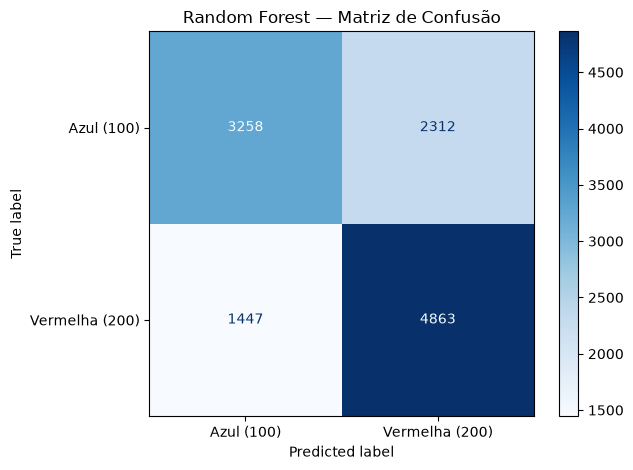

In [17]:
# ============================================================
# CÉLULA 6 — TREINAMENTO E AVALIAÇÃO DA RANDOM FOREST
# ============================================================

import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Verificação dos dados
# ------------------------------------------------------------

if X_treino.empty or X_teste.empty:
    raise ValueError(
        "Os conjuntos de treinamento e teste não podem estar vazios."
    )

if not set(y_treino.unique()).issubset({100, 200}):
    raise ValueError("O conjunto de treinamento contém classes inesperadas.")

# ------------------------------------------------------------
# 2. Diagnóstico dos valores ausentes
# ------------------------------------------------------------

ausentes_treino = X_treino.isnull().sum()
ausentes_teste = X_teste.isnull().sum()

print("VALORES AUSENTES")
print("=" * 60)
print(f"Total no treinamento: {ausentes_treino.sum()}")
print(f"Total no teste:       {ausentes_teste.sum()}")

colunas_com_ausentes = ausentes_treino[ausentes_treino > 0]

if not colunas_com_ausentes.empty:
    print("\nColunas com valores ausentes no treinamento:")
    print(colunas_com_ausentes.sort_values(ascending=False))

# ------------------------------------------------------------
# 3. Tratamento dos valores ausentes
# ------------------------------------------------------------

# Ajustar o imputador exclusivamente com os dados de treinamento.
imputador = SimpleImputer(strategy="median")

X_treino_imputado = imputador.fit_transform(X_treino)
X_teste_imputado = imputador.transform(X_teste)

# Preservar os nomes das características e os índices originais.
colunas_imputadas = imputador.get_feature_names_out()

X_treino = pd.DataFrame(
    X_treino_imputado,
    columns=colunas_imputadas,
    index=X_treino.index
)

X_teste = pd.DataFrame(
    X_teste_imputado,
    columns=colunas_imputadas,
    index=X_teste.index
)

# Confirmar que o tratamento funcionou.
if X_treino.isnull().any().any() or X_teste.isnull().any().any():
    raise ValueError(
        "Ainda existem valores ausentes após a imputação."
    )

print("\nValores ausentes tratados com sucesso.")

# ------------------------------------------------------------
# 4. Criação do modelo
# ------------------------------------------------------------

modelo_rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# 5. Treinamento
# ------------------------------------------------------------

modelo_rf.fit(X_treino, y_treino)

print("Random Forest treinada com sucesso.")

# ------------------------------------------------------------
# 6. Previsões no conjunto de teste
# ------------------------------------------------------------

y_pred_rf = modelo_rf.predict(X_teste)

# ------------------------------------------------------------
# 7. Métricas de avaliação
# ------------------------------------------------------------

acuracia_rf = accuracy_score(y_teste, y_pred_rf)

precisao_rf = precision_score(
    y_teste,
    y_pred_rf,
    labels=[100, 200],
    average="macro",
    zero_division=0
)

revocacao_rf = recall_score(
    y_teste,
    y_pred_rf,
    labels=[100, 200],
    average="macro",
    zero_division=0
)

f1_rf = f1_score(
    y_teste,
    y_pred_rf,
    labels=[100, 200],
    average="macro",
    zero_division=0
)

print("\nRESULTADOS DA RANDOM FOREST")
print("=" * 60)

print(f"Acurácia:           {acuracia_rf:.4f}")
print(f"Precisão (macro):   {precisao_rf:.4f}")
print(f"Revocação (macro):  {revocacao_rf:.4f}")
print(f"F1-score (macro):   {f1_rf:.4f}")

# ------------------------------------------------------------
# 8. Relatório de classificação
# ------------------------------------------------------------

print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("=" * 60)

print(
    classification_report(
        y_teste,
        y_pred_rf,
        labels=[100, 200],
        target_names=["Azul (100)", "Vermelha (200)"],
        zero_division=0
    )
)

# ------------------------------------------------------------
# 9. Matriz de confusão
# ------------------------------------------------------------

print("\nMATRIZ DE CONFUSÃO")
print("=" * 60)

ConfusionMatrixDisplay.from_predictions(
    y_teste,
    y_pred_rf,
    labels=[100, 200],
    display_labels=["Azul (100)", "Vermelha (200)"],
    cmap="Blues",
    values_format="d"
)

plt.title("Random Forest — Matriz de Confusão")
plt.tight_layout()
plt.show()

IMPORTÂNCIA DAS VARIÁVEIS — RANDOM FOREST


,variavel,importancia
0,diff_totalGold,0.065707
1,diff_xp,0.045457
2,diff_kills,0.034176
3,diff_damageStats.totalDamageDone,0.032638
4,diff_deaths,0.030672
...,...,...
67,elder_dragons,0.000027
68,championStats.abilityHaste,0.000000
69,atakhan,0.000000
70,diff_championStats.abilityHaste,0.000000


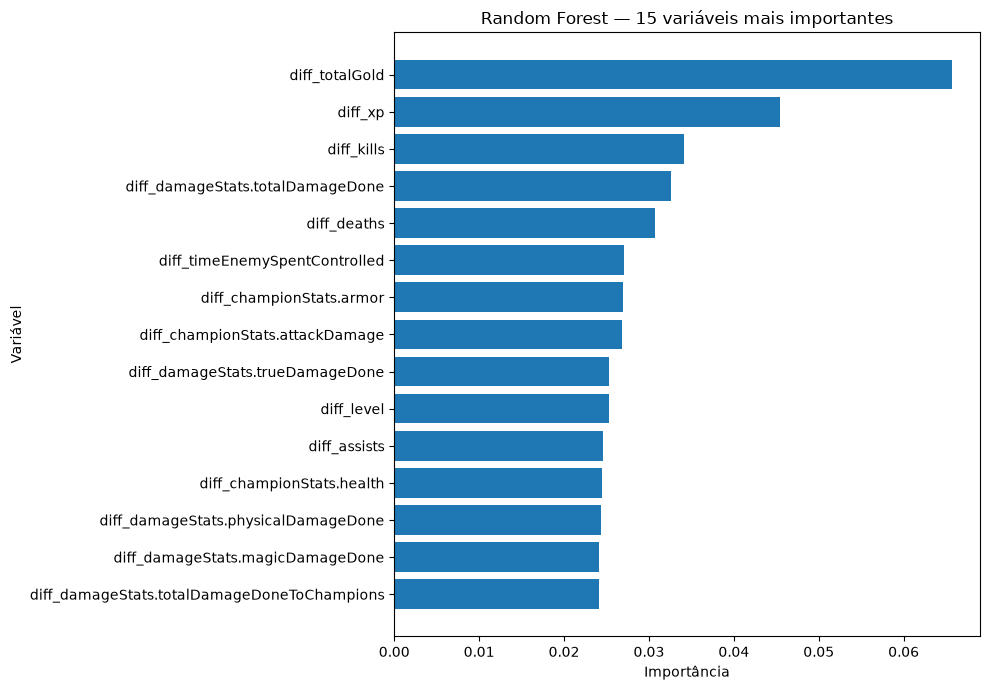


VERIFICAÇÃO
Soma das importâncias: 1.0
Verificação concluída: soma aproximadamente igual a 1.


In [18]:
# ============================================================
# CÉLULA 7 — IMPORTÂNCIA DAS VARIÁVEIS: RANDOM FOREST
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Verificar se o modelo foi treinado
# ------------------------------------------------------------

if not hasattr(modelo_rf, "feature_importances_"):
    raise ValueError(
        "O modelo Random Forest ainda não foi treinado. "
        "Execute primeiro a Célula 6."
    )

if len(X_treino.columns) != len(modelo_rf.feature_importances_):
    raise ValueError(
        "O número de características não corresponde "
        "ao número de importâncias do modelo."
    )

# ------------------------------------------------------------
# 2. Calcular a importância das características
# ------------------------------------------------------------

importancias_rf = pd.DataFrame({
    "variavel": X_treino.columns,
    "importancia": modelo_rf.feature_importances_
})

importancias_rf = importancias_rf.sort_values(
    by="importancia",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# 3. Exibir todas as importâncias
# ------------------------------------------------------------

print("IMPORTÂNCIA DAS VARIÁVEIS — RANDOM FOREST")
print("=" * 60)

# Exibe a tabela sem depender da biblioteca jinja2
display(importancias_rf.round(6))

# ------------------------------------------------------------
# 4. Visualizar as 15 variáveis mais importantes
# ------------------------------------------------------------

top_15_rf = importancias_rf.head(15).sort_values(
    by="importancia",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_15_rf["variavel"].astype(str),
    top_15_rf["importancia"]
)

plt.xlabel("Importância")
plt.ylabel("Variável")
plt.title("Random Forest — 15 variáveis mais importantes")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Verificar a soma das importâncias
# ------------------------------------------------------------

print("\nVERIFICAÇÃO")
print("=" * 60)

soma_importancias_rf = importancias_rf["importancia"].sum()

print(
    "Soma das importâncias:",
    round(soma_importancias_rf, 6)
)

# ------------------------------------------------------------
# 6. Verificar se a soma está dentro do esperado
# ------------------------------------------------------------

if abs(soma_importancias_rf - 1.0) < 1e-6:
    print("Verificação concluída: soma aproximadamente igual a 1.")
else:
    print("Atenção: a soma das importâncias difere de 1.")


In [19]:
%pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 3.0 MB/s  0:00:19 eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 305.1/305.1 MB 2.4 MB/s  0:02:00 eta 0:00:010:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [xgboost]━━━ 1/2 [xgboost]
Note: you may need to restart the kernel to use updated packages.


Distribuição das classes no treinamento:
vencedor
Azul (100)        21654
Vermelha (200)    26382
Name: count, dtype: int64

XGBoost treinado com sucesso.

RESULTADOS DO XGBOOST
Acurácia:           0.6872
Precisão (macro):   0.6916
Revocação (macro):  0.6800
F1-score (macro):   0.6792

RELATÓRIO DE CLASSIFICAÇÃO
                precision    recall  f1-score   support

    Azul (100)       0.71      0.56      0.63      5570
Vermelha (200)       0.67      0.80      0.73      6310

      accuracy                           0.69     11880
     macro avg       0.69      0.68      0.68     11880
  weighted avg       0.69      0.69      0.68     11880


MATRIZ DE CONFUSÃO


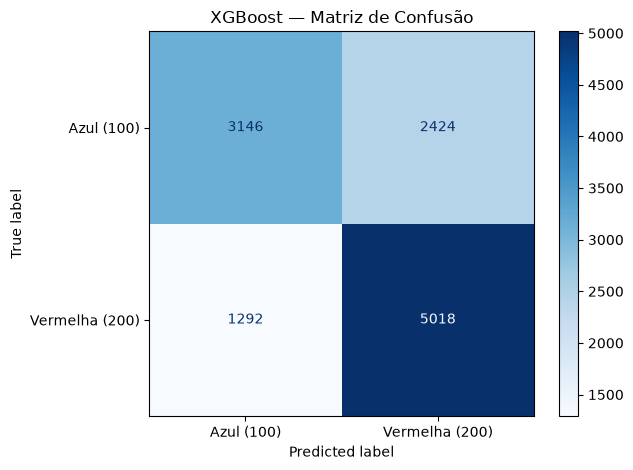

In [20]:
# ============================================================
# CÉLULA 8 — TREINAMENTO E AVALIAÇÃO DO XGBOOST
# ============================================================

# Se necessário, instale o XGBoost em uma célula separada:
# %pip install xgboost

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# 1. Verificações iniciais
# ------------------------------------------------------------

if X_treino.empty or X_teste.empty:
    raise ValueError(
        "Os conjuntos de treinamento e teste não podem estar vazios."
    )

if X_treino.isnull().any().any() or X_teste.isnull().any().any():
    raise ValueError(
        "Existem valores ausentes em X_treino ou X_teste. "
        "Execute o tratamento de valores ausentes antes de continuar."
    )

if y_treino.isnull().any() or y_teste.isnull().any():
    raise ValueError(
        "O alvo contém valores ausentes."
    )

if not set(y_treino.unique()).issubset({100, 200}):
    raise ValueError(
        "O alvo de treinamento deve conter apenas as classes 100 e 200."
    )

if not set(y_teste.unique()).issubset({100, 200}):
    raise ValueError(
        "O alvo de teste deve conter apenas as classes 100 e 200."
    )

if y_treino.nunique() != 2:
    raise ValueError(
        "O conjunto de treinamento precisa conter as duas classes: "
        "100 (Azul) e 200 (Vermelha)."
    )

# ------------------------------------------------------------
# 2. Codificar o alvo para classificação binária
# ------------------------------------------------------------

# 0 = Azul (100)
# 1 = Vermelha (200)

y_treino_xgb = (y_treino == 200).astype(int)
y_teste_xgb = (y_teste == 200).astype(int)

print("Distribuição das classes no treinamento:")
print(y_treino_xgb.value_counts().sort_index().rename(
    index={0: "Azul (100)", 1: "Vermelha (200)"}
))

# ------------------------------------------------------------
# 3. Criar o modelo
# ------------------------------------------------------------

modelo_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# 4. Treinar o modelo
# ------------------------------------------------------------

modelo_xgb.fit(X_treino, y_treino_xgb)

print("\nXGBoost treinado com sucesso.")

# ------------------------------------------------------------
# 5. Fazer previsões no conjunto de teste
# ------------------------------------------------------------

y_pred_xgb = modelo_xgb.predict(X_teste)

# Garantir que as previsões sejam inteiros 0 ou 1
y_pred_xgb = y_pred_xgb.astype(int)

# ------------------------------------------------------------
# 6. Calcular métricas de avaliação
# ------------------------------------------------------------

acuracia_xgb = accuracy_score(
    y_teste_xgb,
    y_pred_xgb
)

precisao_xgb = precision_score(
    y_teste_xgb,
    y_pred_xgb,
    labels=[0, 1],
    average="macro",
    zero_division=0
)

revocacao_xgb = recall_score(
    y_teste_xgb,
    y_pred_xgb,
    labels=[0, 1],
    average="macro",
    zero_division=0
)

f1_xgb = f1_score(
    y_teste_xgb,
    y_pred_xgb,
    labels=[0, 1],
    average="macro",
    zero_division=0
)

print("\nRESULTADOS DO XGBOOST")
print("=" * 60)

print(f"Acurácia:           {acuracia_xgb:.4f}")
print(f"Precisão (macro):   {precisao_xgb:.4f}")
print(f"Revocação (macro):  {revocacao_xgb:.4f}")
print(f"F1-score (macro):   {f1_xgb:.4f}")

# ------------------------------------------------------------
# 7. Relatório de classificação
# ------------------------------------------------------------

print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("=" * 60)

print(
    classification_report(
        y_teste_xgb,
        y_pred_xgb,
        labels=[0, 1],
        target_names=["Azul (100)", "Vermelha (200)"],
        zero_division=0
    )
)

# ------------------------------------------------------------
# 8. Matriz de confusão
# ------------------------------------------------------------

print("\nMATRIZ DE CONFUSÃO")
print("=" * 60)

ConfusionMatrixDisplay.from_predictions(
    y_teste_xgb,
    y_pred_xgb,
    labels=[0, 1],
    display_labels=["Azul (100)", "Vermelha (200)"],
    cmap="Blues",
    values_format="d"
)

plt.title("XGBoost — Matriz de Confusão")
plt.tight_layout()
plt.show()


IMPORTÂNCIA DAS VARIÁVEIS — XGBOOST


,variavel,importancia
0,diff_totalGold,0.153662
1,diff_xp,0.108859
2,diff_inhibitors_destroyed,0.035658
3,diff_towers_destroyed,0.033474
4,diff_dragons,0.031188
...,...,...
67,atakhan,0.000000
68,barons,0.000000
69,elder_dragons,0.000000
70,dragons,0.000000


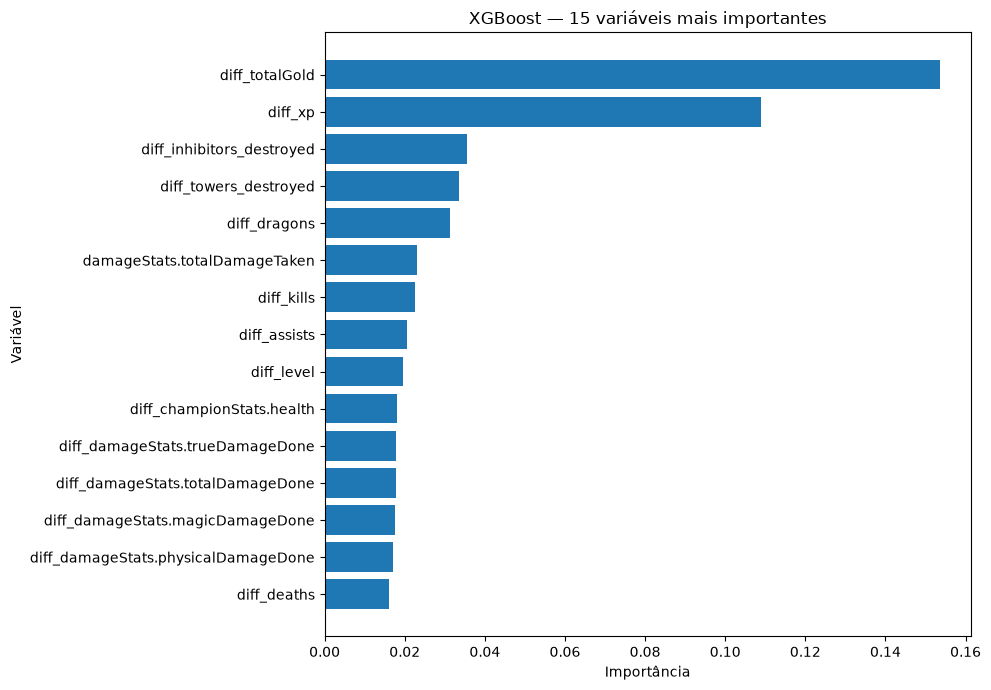


VERIFICAÇÃO
Soma das importâncias: 1.0
Verificação concluída: soma aproximadamente igual a 1.


In [21]:
# ============================================================
# CÉLULA 9 — IMPORTÂNCIA DAS VARIÁVEIS NO XGBOOST
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Verificar se o modelo foi treinado
# ------------------------------------------------------------

if not hasattr(modelo_xgb, "feature_importances_"):
    raise ValueError(
        "O modelo XGBoost ainda não foi treinado. "
        "Execute primeiro a Célula 8."
    )

if len(X_treino.columns) != len(modelo_xgb.feature_importances_):
    raise ValueError(
        "O número de características não corresponde "
        "ao número de importâncias do modelo."
    )

# ------------------------------------------------------------
# 2. Extrair a importância das características
# ------------------------------------------------------------

importancias_xgb = pd.DataFrame({
    "variavel": X_treino.columns,
    "importancia": modelo_xgb.feature_importances_
}).sort_values(
    by="importancia",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# 3. Exibir o ranking completo
# ------------------------------------------------------------

print("IMPORTÂNCIA DAS VARIÁVEIS — XGBOOST")
print("=" * 60)

# Exibir sem depender da biblioteca jinja2
display(importancias_xgb.round(6))

# ------------------------------------------------------------
# 4. Gráfico das 15 variáveis mais importantes
# ------------------------------------------------------------

top_15_xgb = importancias_xgb.head(15).sort_values(
    by="importancia",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_15_xgb["variavel"].astype(str),
    top_15_xgb["importancia"]
)

plt.xlabel("Importância")
plt.ylabel("Variável")
plt.title("XGBoost — 15 variáveis mais importantes")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Verificar a soma das importâncias
# ------------------------------------------------------------

soma_importancias_xgb = importancias_xgb["importancia"].sum()

print("\nVERIFICAÇÃO")
print("=" * 60)

print(
    "Soma das importâncias:",
    round(soma_importancias_xgb, 6)
)

if abs(soma_importancias_xgb - 1.0) < 1e-6:
    print("Verificação concluída: soma aproximadamente igual a 1.")
else:
    print("Atenção: a soma das importâncias difere de 1.")


In [22]:
# ============================================================
# CÉLULA 10 — COMPARAÇÃO DA IMPORTÂNCIA DAS VARIÁVEIS
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. Verificar se os rankings dos dois modelos existem
# ------------------------------------------------------------

if "importancias_rf" not in globals():
    raise ValueError(
        "O ranking do Random Forest não foi encontrado. "
        "Execute primeiro a Célula 7."
    )

if "importancias_xgb" not in globals():
    raise ValueError(
        "O ranking do XGBoost não foi encontrado. "
        "Execute primeiro a Célula 9."
    )

# ------------------------------------------------------------
# 2. Preparar o ranking do Random Forest
# ------------------------------------------------------------

comparacao_importancias = importancias_rf[
    ["variavel", "importancia"]
].copy()

comparacao_importancias = comparacao_importancias.rename(
    columns={"importancia": "importancia_rf"}
)

comparacao_importancias["ranking_rf"] = range(
    1, len(comparacao_importancias) + 1
)

# ------------------------------------------------------------
# 3. Preparar o ranking do XGBoost
# ------------------------------------------------------------

ranking_xgb = importancias_xgb[
    ["variavel", "importancia"]
].copy()

ranking_xgb = ranking_xgb.rename(
    columns={"importancia": "importancia_xgb"}
)

ranking_xgb["ranking_xgb"] = ranking_xgb[
    "importancia_xgb"
].rank(
    method="first",
    ascending=False
).astype(int)

# ------------------------------------------------------------
# 4. Combinar os rankings dos dois modelos
# ------------------------------------------------------------

comparacao_importancias = comparacao_importancias.merge(
    ranking_xgb,
    on="variavel",
    how="inner",
    validate="one_to_one"
)

if comparacao_importancias.empty:
    raise ValueError(
        "Não existem variáveis em comum entre os rankings "
        "do Random Forest e do XGBoost."
    )

# ------------------------------------------------------------
# 5. Identificar variáveis presentes no Top 10 de cada modelo
# ------------------------------------------------------------

comparacao_importancias["top_10_rf"] = (
    comparacao_importancias["ranking_rf"] <= 10
)

comparacao_importancias["top_10_xgb"] = (
    comparacao_importancias["ranking_xgb"] <= 10
)

comparacao_importancias["top_10_ambos"] = (
    comparacao_importancias["top_10_rf"]
    & comparacao_importancias["top_10_xgb"]
)

# ------------------------------------------------------------
# 6. Ordenar pela posição no Random Forest
# ------------------------------------------------------------

comparacao_importancias = comparacao_importancias.sort_values(
    by="ranking_rf"
).reset_index(drop=True)

print("COMPARAÇÃO DA IMPORTÂNCIA DAS VARIÁVEIS")
print("=" * 80)

# Exibir a tabela sem depender da biblioteca jinja2
display(comparacao_importancias.round({
    "importancia_rf": 6,
    "importancia_xgb": 6
}))

# ------------------------------------------------------------
# 7. Exibir variáveis presentes no Top 10 dos dois modelos
# ------------------------------------------------------------

variaveis_comuns = comparacao_importancias[
    comparacao_importancias["top_10_ambos"]
].sort_values(
    by="ranking_rf"
)

print("\nVARIÁVEIS PRESENTES NO TOP 10 DOS DOIS MODELOS")
print("=" * 80)

if variaveis_comuns.empty:
    print("Nenhuma variável aparece no Top 10 dos dois modelos.")
else:
    colunas_exibicao = [
        "variavel",
        "importancia_rf",
        "ranking_rf",
        "importancia_xgb",
        "ranking_xgb"
    ]

    display(
        variaveis_comuns[colunas_exibicao].round({
            "importancia_rf": 6,
            "importancia_xgb": 6
        })
    )

print(
    f"\nQuantidade de variáveis no Top 10 de ambos: "
    f"{len(variaveis_comuns)}"
)

# ------------------------------------------------------------
# 8. Resumo da comparação
# ------------------------------------------------------------

print("\nRESUMO")
print("=" * 80)

print(
    "Total de variáveis comparadas:",
    len(comparacao_importancias)
)

print(
    "Variáveis no Top 10 do Random Forest:",
    int(comparacao_importancias["top_10_rf"].sum())
)

print(
    "Variáveis no Top 10 do XGBoost:",
    int(comparacao_importancias["top_10_xgb"].sum())
)

print(
    "Variáveis no Top 10 dos dois modelos:",
    len(variaveis_comuns)
)


COMPARAÇÃO DA IMPORTÂNCIA DAS VARIÁVEIS


,variavel,importancia_rf,ranking_rf,importancia_xgb,ranking_xgb,top_10_rf,top_10_xgb,top_10_ambos
0,diff_totalGold,0.065707,1,0.153662,1,True,True,True
1,diff_xp,0.045457,2,0.108859,2,True,True,True
2,diff_kills,0.034176,3,0.022451,7,True,True,True
3,diff_damageStats.totalDamageDone,0.032638,4,0.017741,12,True,False,False
4,diff_deaths,0.030672,5,0.015984,15,True,False,False
...,...,...,...,...,...,...,...,...
67,elder_dragons,0.000027,68,0.000000,70,False,False,False
68,championStats.abilityHaste,0.000000,69,0.000000,62,False,False,False
69,atakhan,0.000000,70,0.000000,68,False,False,False
70,diff_championStats.abilityHaste,0.000000,71,0.000000,66,False,False,False



VARIÁVEIS PRESENTES NO TOP 10 DOS DOIS MODELOS


,variavel,importancia_rf,ranking_rf,importancia_xgb,ranking_xgb
0,diff_totalGold,0.065707,1,0.153662,1
1,diff_xp,0.045457,2,0.108859,2
2,diff_kills,0.034176,3,0.022451,7
9,diff_level,0.025252,10,0.019604,9



Quantidade de variáveis no Top 10 de ambos: 4

RESUMO
Total de variáveis comparadas: 72
Variáveis no Top 10 do Random Forest: 10
Variáveis no Top 10 do XGBoost: 10
Variáveis no Top 10 dos dois modelos: 4
